/tmp/ipykernel_151605/649223529.py:4: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  pca = pd.read_csv("data/ukb22418_all_chr_b0_v2_filtered_qc-ed_no_mhc_ld_pca_approx.eigenvec", delim_whitespace=True)


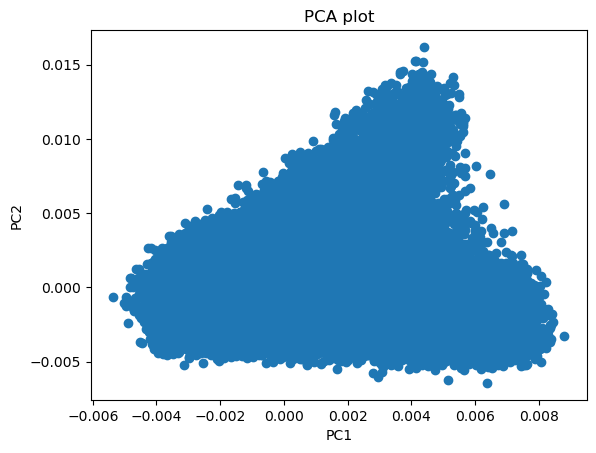

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pca = pd.read_csv("data/ukb22418_all_chr_b0_v2_filtered_qc-ed_no_mhc_ld_pca_approx.eigenvec", delim_whitespace=True)

plt.scatter(pca["PC1"], pca["PC2"])
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA plot")
#plt.savefig("pcs_plot_nocluster.pdf", dpi=150, bbox_inches="tight")
plt.show()

/tmp/ipykernel_151605/3678438322.py:4: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  gwas = pd.read_csv("data/ukb22418_all_chr_b0_v2_filtered_qc-ed_no_mhc_ld.assoc", delim_whitespace=True)
/home/giannkas/miniconda3/envs/rnaseq/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


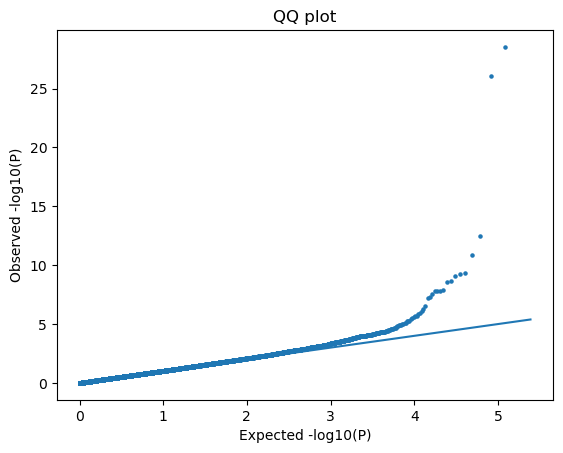

In [2]:
import numpy as np
from scipy import stats

gwas = pd.read_csv("data/ukb22418_all_chr_b0_v2_filtered_qc-ed_no_mhc_ld.assoc", delim_whitespace=True)

p = gwas["P"].sort_values()

expected = -np.log10(np.arange(1, len(p)+1) / (len(p)+1))
observed = -np.log10(p)

plt.scatter(expected, observed, s=5)
plt.plot([0, max(expected)], [0, max(expected)])
plt.xlabel("Expected -log10(P)")
plt.ylabel("Observed -log10(P)")
plt.title("QQ plot")
#plt.savefig("qq_plot_nodeviation.pdf", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from upsetplot import UpSet, from_contents
from matplotlib.text import Text
import numpy as np

bioGRID: 128 elements
HINT: 101 elements
IID: 258 elements
IntAct: 59 elements
STRING: 239 elements


/home/giannkas/miniconda3/envs/rnaseq/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/home/giannkas/miniconda3/envs/rnaseq/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  style

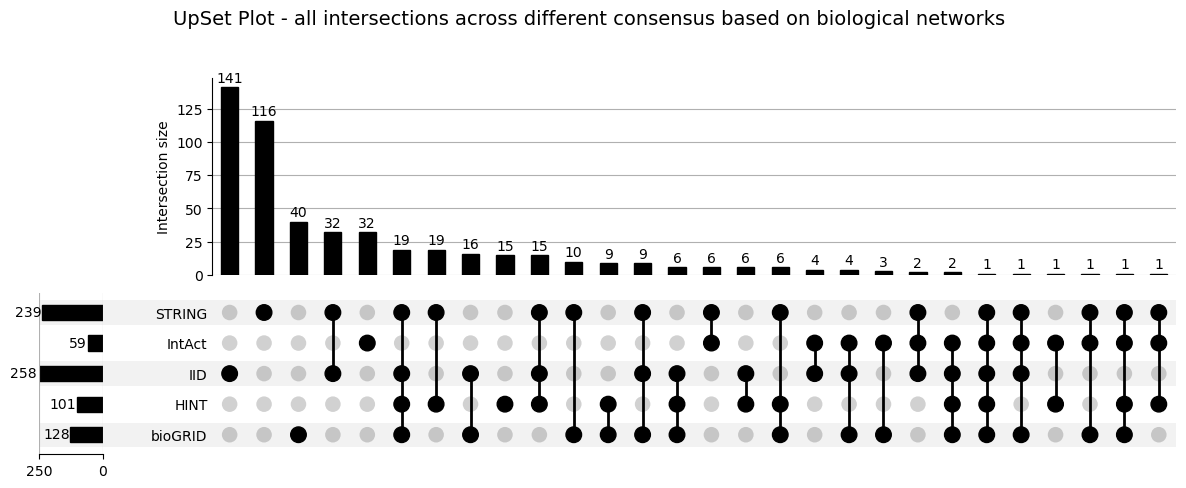

In [37]:
FILES = {
   # 'bioGRID' and 'baseline_bioGRID' are the same, but we keep both for labeling purposes
    "bioGRID": "data/consensus_44249.tsv",
    "HINT": "data/consensus_hint.tsv",
    "IID": "data/consensus_iid.tsv",
    "IntAct": "data/consensus_intact.tsv",
    "STRING": "data/consensus_string.tsv",
    # "finngen": "data/consensus_finngen.tsv",
    # "no_mhc_covars_bioGRID": "data/consensus_no_mhc_covars.tsv",
}

def load_set(path: str) -> set:
    """Read the first column of a TSV (skipping header) and return a set."""
    df = pd.read_csv(path, sep="\t", usecols=[0], header=0)
    return set(df.iloc[:, 0].dropna().astype(str))


sets = {name: load_set(path) for name, path in FILES.items()}

for name, s in sets.items():
    print(f"{name}: {len(s)} elements")


# ── 2.  UpSet plot (handles any number of sets) ───────────────────────────────
upset_data = from_contents(sets)

fig = plt.figure(figsize=(14, 6))
upset = UpSet(
    upset_data,
    subset_size="auto",
    show_counts=True,
    sort_by="cardinality",      # largest intersections first
    sort_categories_by=None,
)
# upset.plot(fig)
axes = upset.plot(fig)
axes["totals"].set_xlim(250, 0)
for ax in fig.axes:
  for text in ax.findobj(match=Text):
    x, y = text.get_position()
    if np.ndim(x) and np.size(x) == 1:
      x = np.asarray(x).item()
    if np.ndim(y) and np.size(y) == 1:
      y = np.asarray(y).item()
    text.set_position((x, y))
plt.suptitle("UpSet Plot - all intersections across different consensus based on biological networks", fontsize=14, y=1.02)
# plt.savefig("upset_plot.pdf", dpi=150, bbox_inches="tight")
plt.show()
# print("Saved: upset_plot.png")


In [38]:
from itertools import combinations

# Elements present in at least 4 out of 5 sets
names = list(sets.keys())
at_least_4 = set()

for combo in combinations(names, 4):
    at_least_4 |= set.intersection(*(sets[n] for n in combo))

print(f"\nElements in at least 4 sets ({len(at_least_4)}):")
for element in sorted(at_least_4):
    print(f"  {element}")


Elements in at least 4 sets (24):
  BAG6
  BRD2
  CCHCR1
  CDC37
  CSNK2B
  HLA-A
  HLA-B
  HLA-C
  HLA-G
  HSPA1B
  IFIH1
  MDC1
  MRPL38
  PSMA6
  PSMB8
  PSMB9
  RAD50
  REL
  RNF5
  STAT2
  TAP1
  TAP2
  TAPBP
  TYK2


In [39]:
for element in sorted(at_least_4):
    present_in = [name for name, s in sets.items() if element in s]
    print(f"  {element}: found in {present_in}")

  BAG6: found in ['bioGRID', 'HINT', 'IID', 'STRING']
  BRD2: found in ['bioGRID', 'HINT', 'IID', 'STRING']
  CCHCR1: found in ['bioGRID', 'HINT', 'IID', 'STRING']
  CDC37: found in ['bioGRID', 'HINT', 'IID', 'STRING']
  CSNK2B: found in ['bioGRID', 'HINT', 'IID', 'IntAct']
  HLA-A: found in ['bioGRID', 'HINT', 'IID', 'STRING']
  HLA-B: found in ['bioGRID', 'HINT', 'IID', 'STRING']
  HLA-C: found in ['bioGRID', 'HINT', 'IID', 'STRING']
  HLA-G: found in ['bioGRID', 'HINT', 'IID', 'STRING']
  HSPA1B: found in ['bioGRID', 'HINT', 'IID', 'STRING']
  IFIH1: found in ['bioGRID', 'IID', 'IntAct', 'STRING']
  MDC1: found in ['bioGRID', 'HINT', 'IID', 'IntAct', 'STRING']
  MRPL38: found in ['bioGRID', 'HINT', 'IID', 'STRING']
  PSMA6: found in ['bioGRID', 'HINT', 'IID', 'STRING']
  PSMB8: found in ['bioGRID', 'HINT', 'IID', 'STRING']
  PSMB9: found in ['bioGRID', 'HINT', 'IID', 'STRING']
  RAD50: found in ['bioGRID', 'HINT', 'IntAct', 'STRING']
  REL: found in ['bioGRID', 'HINT', 'IID', 'STRIN

In [40]:
elements_to_search = [
    "MRPL4",
    "MRPL24",
    "MRPL38",
    "DDX28",
    "CS",
    "VARS2",
    "MRPS18B",
]

print("\nSet membership for searched elements:")
for element in elements_to_search:
    present_in = [name for name, s in sets.items() if element in s]
    if present_in:
        print(f"  {element}: found in {present_in}")
    else:
        print(f"  {element}: not found in any set")


Set membership for searched elements:
  MRPL4: found in ['bioGRID', 'STRING']
  MRPL24: found in ['bioGRID']
  MRPL38: found in ['bioGRID', 'HINT', 'IID', 'STRING']
  DDX28: found in ['bioGRID', 'HINT', 'STRING']
  CS: found in ['bioGRID', 'IID', 'STRING']
  VARS2: found in ['bioGRID']
  MRPS18B: found in ['bioGRID', 'HINT', 'STRING']


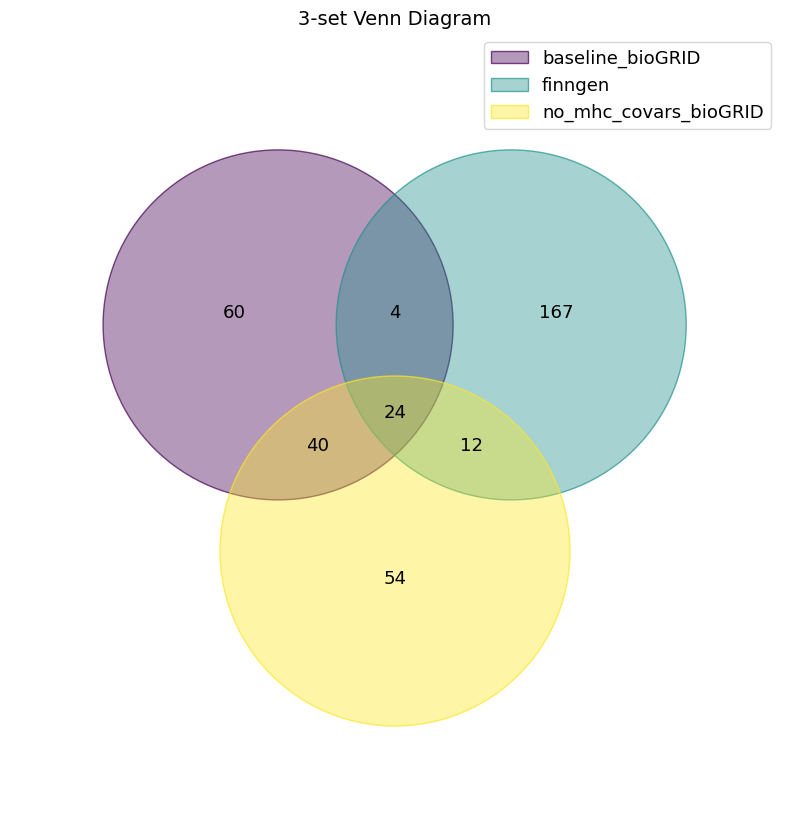


── Pairwise intersections ──
  baseline_bioGRID∩finngen: 28
  baseline_bioGRID∩no_mhc_covars_bioGRID: 64
  finngen∩no_mhc_covars_bioGRID: 36
  baseline_bioGRID∩finngen∩no_mhc_covars_bioGRID: 24


In [42]:
FILES = {
    # 'bioGRID' and 'baseline_bioGRID' are the same, but we keep both for labeling purposes
    "baseline_bioGRID": "data/consensus_44249.tsv",
    "finngen": "data/consensus_finngen.tsv",
    "no_mhc_covars_bioGRID": "data/consensus_no_mhc_covars.tsv",
}

sets = {name: load_set(path) for name, path in FILES.items()}

try:
    from venn import venn as venn3          # pip install venn
    fig, ax = plt.subplots(figsize=(10, 10))
    venn3(sets, ax=ax)
    ax.set_title("3-set Venn Diagram", fontsize=14)
    # plt.savefig("venn_3set.pdf", dpi=150, bbox_inches="tight")
    plt.show()
    # print("Saved: venn_3set.pdf")
except ImportError:
    print(
        "3-set Venn skipped – install the 'venn' package:  pip install venn\n"
        "The UpSet plot above already shows all intersections."
    )


# ── 4.  Print intersection sizes as a reference table ────────────────────────
from itertools import combinations

print("\n── Pairwise intersections ──")
names = list(sets.keys())
for r in range(2, len(names) + 1):
    for combo in combinations(names, r):
        common = set.intersection(*(sets[n] for n in combo))
        print(f"  {'∩'.join(combo)}: {len(common)}")


In [ ]:
from itertools import combinations

# Elements present in at least 2 out of 3 sets
names = list(sets.keys())
at_least_2 = set()

for combo in combinations(names, 2):
    at_least_2 |= set.intersection(*(sets[n] for n in combo))

print(f"\nElements in at least 2 sets ({len(at_least_2)}):")
for element in sorted(at_least_2):
    print(f"  {element}")


Elements in at least 2 sets (80):
  ANKRD52
  B3GNT2
  BPTF
  CAMK2G
  CDC37
  CDC7
  CLEC16A
  CS
  CTSB
  DDX28
  DNMT3B
  ELL
  EPHA5
  EPHA7
  ERBB3
  ERLIN1
  ESRRA
  ETS1
  FAS
  FBXO45
  FGF2
  GRB7
  GTSE1
  ICE1
  IFIH1
  IFNLR1
  IKZF3
  IKZF4
  INSRR
  IRF1
  ITPR3
  KEAP1
  LPP
  MAGI1
  MAZ
  MBD2
  MFN2
  MRPL24
  MRPL38
  MRPL4
  MTCH1
  NABP2
  NFKB1
  NFKBIA
  NOS2
  NRG1
  PAAF1
  PLAU
  PSMA6
  PSMG2
  PTPN2
  RAB5B
  RAD50
  RBM17
  RDX
  REL
  RHOU
  RNF114
  RNF41
  RPS26
  RPS6KA4
  RUNX3
  S100A10
  SERBP1
  SLC39A5
  SNAI1
  SNAI2
  SPATA2
  STAMBPL1
  STAT2
  TNFAIP3
  TRAF3IP2
  TRIM65
  TYK2
  UBLCP1
  ULBP3
  USP3
  USP8
  VANGL2
  ZBTB24


In [44]:
for element in sorted(at_least_2):
    present_in = [name for name, s in sets.items() if element in s]
    print(f"  {element}: found in {present_in}")

  ANKRD52: found in ['finngen', 'no_mhc_covars_bioGRID']
  B3GNT2: found in ['baseline_bioGRID', 'no_mhc_covars_bioGRID']
  BPTF: found in ['baseline_bioGRID', 'no_mhc_covars_bioGRID']
  CAMK2G: found in ['baseline_bioGRID', 'finngen']
  CDC37: found in ['baseline_bioGRID', 'finngen', 'no_mhc_covars_bioGRID']
  CDC7: found in ['baseline_bioGRID', 'finngen', 'no_mhc_covars_bioGRID']
  CLEC16A: found in ['baseline_bioGRID', 'finngen', 'no_mhc_covars_bioGRID']
  CS: found in ['baseline_bioGRID', 'finngen', 'no_mhc_covars_bioGRID']
  CTSB: found in ['baseline_bioGRID', 'no_mhc_covars_bioGRID']
  DDX28: found in ['baseline_bioGRID', 'no_mhc_covars_bioGRID']
  DNMT3B: found in ['baseline_bioGRID', 'finngen', 'no_mhc_covars_bioGRID']
  ELL: found in ['baseline_bioGRID', 'finngen', 'no_mhc_covars_bioGRID']
  EPHA5: found in ['baseline_bioGRID', 'no_mhc_covars_bioGRID']
  EPHA7: found in ['baseline_bioGRID', 'no_mhc_covars_bioGRID']
  ERBB3: found in ['baseline_bioGRID', 'no_mhc_covars_bioGRID'

In [45]:
elements_to_search = [
    "MRPL4",
    "MRPL24",
    "MRPL38",
    "DDX28",
    "CS",
    "VARS2",
    "MRPS18B",
]

print("\nSet membership for searched elements:")
for element in elements_to_search:
    present_in = [name for name, s in sets.items() if element in s]
    if present_in:
        print(f"  {element}: found in {present_in}")
    else:
        print(f"  {element}: not found in any set")


Set membership for searched elements:
  MRPL4: found in ['baseline_bioGRID', 'finngen', 'no_mhc_covars_bioGRID']
  MRPL24: found in ['baseline_bioGRID', 'no_mhc_covars_bioGRID']
  MRPL38: found in ['baseline_bioGRID', 'no_mhc_covars_bioGRID']
  DDX28: found in ['baseline_bioGRID', 'no_mhc_covars_bioGRID']
  CS: found in ['baseline_bioGRID', 'finngen', 'no_mhc_covars_bioGRID']
  VARS2: found in ['baseline_bioGRID']
  MRPS18B: found in ['baseline_bioGRID']
